In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

dados = load_breast_cancer()
X, y = dados.data, dados.target
print("X:", X.shape, "| y:", y.shape, "| classes:", np.bincount(y))


X: (569, 30) | y: (569,) | classes: [212 357]


Utilizando os códigos de sala

In [13]:
def meu_kfold(n_amostras, k=5, shuffle=False, random_state=None):
    indices = np.arange(n_amostras)
    if shuffle:
        rng = np.random.default_rng(random_state)
        indices = rng.permutation(indices)
    tamanhos = np.full(k, n_amostras // k)
    tamanhos[: n_amostras % k] += 1
    inicio = 0
    for tamanho in tamanhos:
        fim = inicio + tamanho
        val_idx = indices[inicio:fim]
        train_idx = np.concatenate([indices[:inicio], indices[fim:]])
        yield train_idx, val_idx
        inicio = fim

def meu_stratified_kfold(y, k=5, shuffle=False, random_state=None):
    y = np.asarray(y)
    classes, contagens = np.unique(y, return_counts=True)
    rng = np.random.default_rng(random_state)
    partes_por_fold = [[] for _ in range(k)]
    for c in classes:
        idx_c = np.flatnonzero(y == c)
        if shuffle:
            idx_c = rng.permutation(idx_c)
        for f, parte in enumerate(np.array_split(idx_c, k)):
            partes_por_fold[f].append(parte)
    todos = np.arange(len(y))
    for partes in partes_por_fold:
        val_idx = np.sort(np.concatenate(partes))
        train_idx = np.setdiff1d(todos, val_idx)
        yield train_idx, val_idx

def acuracia(y_true, y_pred):
    return np.mean(y_true == y_pred)

def meu_cross_val_score(modelo_factory, X, y, folds, metrica=acuracia):
    scores = []
    for train_idx, val_idx in folds:
        X_treino, y_treino = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]
        modelo = modelo_factory()
        modelo.fit(X_treino, y_treino)
        y_pred = modelo.predict(X_val)
        scores.append(metrica(y_val, y_pred))
    return np.array(scores)


In [14]:
folds = list(meu_stratified_kfold(y, k=5, shuffle=True, random_state=42))

print("Distribuição das classes nos folds:")
for i, (train_idx, val_idx) in enumerate(folds, start=1):
    dist = np.bincount(y[val_idx])
    print(f"Fold {i}: val={len(val_idx)} (classe 0: {dist[0]}, classe 1: {dist[1]}) | primeiros índices: {val_idx[:5]}")

scores = meu_cross_val_score(lambda: LogisticRegression(max_iter=10000), X, y, folds)
print("\nScores individuais  :", scores.round(4))
print(f"Média e desvio-padrão: {scores.mean():.4f} +- {scores.std():.4f}")

# Comparação com o scikit-learn
scores_sk = cross_val_score(LogisticRegression(max_iter=10000), X, y, cv=folds)
print("Scores scikit-learn  :", scores_sk.round(4))
print(np.allclose(scores, scores_sk))


Distribuição das classes nos folds:
Fold 1: val=115 (classe 0: 43, classe 1: 72) | primeiros índices: [ 7  9 23 27 28]
Fold 2: val=115 (classe 0: 43, classe 1: 72) | primeiros índices: [0 2 3 4 8]
Fold 3: val=113 (classe 0: 42, classe 1: 71) | primeiros índices: [ 5 13 18 20 21]
Fold 4: val=113 (classe 0: 42, classe 1: 71) | primeiros índices: [ 1 10 11 17 24]
Fold 5: val=113 (classe 0: 42, classe 1: 71) | primeiros índices: [ 6 14 15 16 22]

Scores individuais  : [0.9478 0.9565 0.9646 0.9558 0.9381]
Média e desvio-padrão: 0.9526 +- 0.0090
Scores scikit-learn  : [0.9478 0.9565 0.9646 0.9558 0.9381]
True


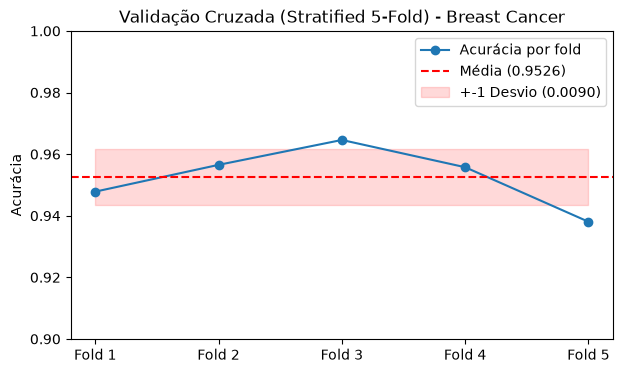

In [15]:
# Gráfico dos scores
x_folds = [f"Fold {i}" for i in range(1, len(scores) + 1)]
plt.figure(figsize=(7, 4))
plt.plot(x_folds, scores, "o-", label="Acurácia por fold")
plt.axhline(scores.mean(), color="r", linestyle="--", label=f"Média ({scores.mean():.4f})")
plt.fill_between(range(len(scores)), scores.mean() - scores.std(), scores.mean() + scores.std(), color="r", alpha=0.15, label=f"+-1 Desvio ({scores.std():.4f})")
plt.ylim(0.90, 1.0)
plt.ylabel("Acurácia")
plt.title("Validação Cruzada (Stratified 5-Fold) - Breast Cancer")
plt.legend()
plt.show()
